# Biomass supply chain: Python analysis and a one-line description, for example Cross-checks the SQL results and draws charts. Data: ../data/*.csv

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data")

## 1. Load the data

In [26]:
supplier = pd.read_csv(DATA / "01_supplier.csv", parse_dates=["effective_from", "effective_to"])
customer = pd.read_csv(DATA / "02_customer.csv", parse_dates=["effective_date"])
deliveries = pd.read_csv(DATA / "03_deliveries.csv", parse_dates=["date", "month"])
gross_profit = pd.read_csv(DATA / "04_gross_profit.csv", parse_dates=["month"])
purchases = pd.read_csv(DATA / "05_purchasing_history.csv", parse_dates=["date"])

for name, df in [("supplier", supplier), ("customer", customer), ("deliveries", deliveries),
                 ("gross_profit", gross_profit), ("purchases", purchases)]:
    print(name, df.shape)

supplier (10, 8)
customer (24, 7)
deliveries (223, 10)
gross_profit (31, 14)
purchases (20, 11)


## 2. Validate totals (expected: 2,136,200 kg and Rp 203,606,340)

In [27]:
print("Total kg:", deliveries["qty_kg"].sum())
print("Gross profit:", gross_profit["total_gross_profit"].sum())

Total kg: 2136200
Gross profit: 203606340


## 3. Volume share vs profit share by supplier 

In [28]:
kg = deliveries.groupby("supplier_id")["qty_kg"].sum().rename("kg")
gp = gross_profit.groupby("supplier_id")["total_gross_profit"].sum().rename("gross_profit")

summary = pd.concat([kg, gp], axis=1)
summary["kg_share_pct"] = (summary["kg"] / summary["kg"].sum() * 100).round(1)
summary["profit_share_pct"] = (summary["gross_profit"] / summary["gross_profit"].sum() * 100).round(1)
summary["profit_per_kg"] = (summary["gross_profit"] / summary["kg"]).round(1)
summary = summary.sort_values("kg", ascending=False)
summary

,kg,gross_profit,kg_share_pct,profit_share_pct,profit_per_kg
supplier_id,,,,,
STP,745350,51680750,34.9,25.4,69.3
BSP,298880,21747740,14.0,10.7,72.8
STD,267440,43914800,12.5,21.6,164.2
SAF,261460,20084680,12.2,9.9,76.8
BGM,166090,6245700,7.8,3.1,37.6
BIS,161260,24889590,7.5,12.2,154.3
PMK,97630,14546870,4.6,7.1,149.0
KMB,92740,13965810,4.3,6.9,150.6
SSP,45350,6530400,2.1,3.2,144.0


**Finding:** STP supplies 34.9% of the volume but only 25.4% of the profit (Rp 69 per kg), while STD earns Rp 164 per kg on 12.5% of the volume.

### Chart: volume share vs profit share

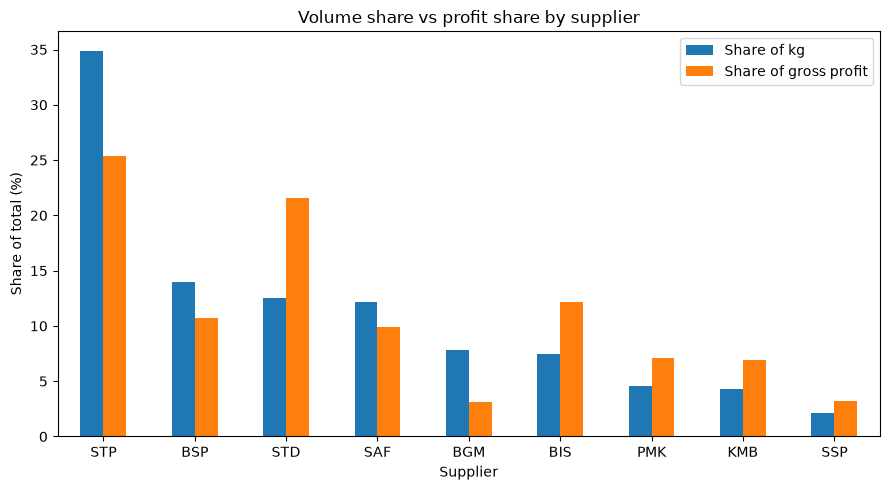

In [29]:
ax = summary[["kg_share_pct", "profit_share_pct"]].plot(kind="bar", figsize=(9, 5))
ax.set_title("Volume share vs profit share by supplier")
ax.set_xlabel("Supplier")
ax.set_ylabel("Share of total (%)")
ax.legend(["Share of kg", "Share of gross profit"])
plt.xticks(rotation=0)
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/volume_vs_profit_share.png", dpi=150)
plt.show()

## 4. September vs October

In [30]:
monthly = gross_profit.groupby("month").agg(kg=("qty_delivered_kg", "sum"),
                                            gross_profit=("total_gross_profit", "sum"))
monthly["profit_per_kg"] = (monthly["gross_profit"] / monthly["kg"]).round(1)
monthly["kg_change_pct"] = (monthly["kg"].pct_change() * 100).round(1)
monthly["profit_change_pct"] = (monthly["gross_profit"].pct_change() * 100).round(1)
monthly

,kg,gross_profit,profit_per_kg,kg_change_pct,profit_change_pct
month,,,,,
2026-09-01,1206130,116180570,96.3,NaN,NaN
2026-10-01,930070,87425770,94.0,-22.9,-24.8


## 5. Join deliveries to routes (with a safety check)

In [31]:
merged = deliveries.merge(
    gross_profit[["delivery_code", "month", "unit_profit_per_kg"]],
    left_on=["delivery_ref", "month"], right_on=["delivery_code", "month"],
    how="left", validate="many_to_one")

print("rows after join:", len(merged), "| rows without a route:", merged["unit_profit_per_kg"].isna().sum())
merged["gross_profit"] = merged["qty_kg"] * merged["unit_profit_per_kg"]
print("Gross profit:", merged["gross_profit"].sum())

rows after join: 223 | rows without a route: 0
Gross profit: 203606340


## 6. Profit per customer

In [32]:
by_customer = merged.groupby("customer_id").agg(total_kg=("qty_kg", "sum"),
                                                gross_profit=("gross_profit", "sum"))
by_customer["profit_per_kg"] = (by_customer["gross_profit"] / by_customer["total_kg"]).round(1)
by_customer.sort_values("gross_profit", ascending=False)

,total_kg,gross_profit,profit_per_kg
customer_id,,,
BUMI,740110,74754800,101.0
AGRO,497020,52967930,106.6
JAGO,271520,27085300,99.8
VINA,326190,24239070,74.3
YAKIN,275520,20273860,73.6
ORCA,17420,2769780,159.0
CAKRA,8420,1515600,180.0


## 7. Month-over-month volume per supplier month	

In [33]:
pivot = deliveries.pivot_table(index="supplier_id", columns="month", values="qty_kg", aggfunc="sum")
pivot.columns = ["sept_kg", "oct_kg"]
pivot["change_pct"] = ((pivot["oct_kg"] / pivot["sept_kg"] - 1) * 100).round(1)
pivot

,sept_kg,oct_kg,change_pct
supplier_id,,,
BGM,102570.0,63520.0,-38.1
BIS,143840.0,17420.0,-87.9
BSP,184160.0,114720.0,-37.7
KMB,92740.0,NaN,NaN
PMK,NaN,97630.0,NaN
SAF,161970.0,99490.0,-38.6
SSP,45350.0,NaN,NaN
STD,161030.0,106410.0,-33.9
STP,314470.0,430880.0,37.0


### Chart: profit per kg by supplier

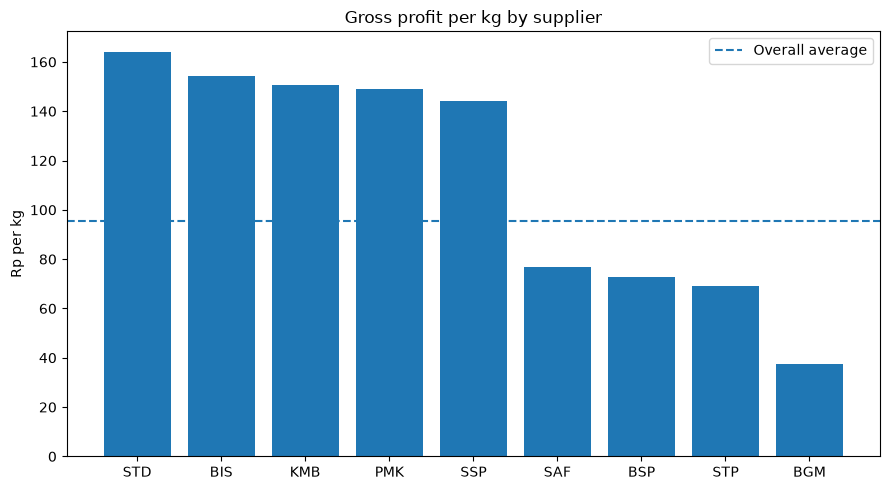

In [34]:
fig, ax = plt.subplots(figsize=(9, 5))
s = summary.sort_values("profit_per_kg", ascending=False)
ax.bar(s.index, s["profit_per_kg"])
ax.axhline(summary["gross_profit"].sum() / summary["kg"].sum(), linestyle="--", label="Overall average")
ax.set_title("Gross profit per kg by supplier")
ax.set_ylabel("Rp per kg")
ax.legend()
plt.tight_layout()
plt.savefig("figures/profit_per_kg_by_supplier.png", dpi=150)
plt.show()

In [35]:
export = merged[["delivery_id", "date", "month", "week", "supplier_id", "customer_id",
                 "loading_port_id", "delivery_ref", "qty_kg", "unit_profit_per_kg", "gross_profit"]]

Path("../dashboard").mkdir(exist_ok=True)
export.to_csv("../dashboard/deliveries_with_profit.csv", index=False)

check = pd.read_csv("../dashboard/deliveries_with_profit.csv")
print(check.shape, check["qty_kg"].sum(), check["gross_profit"].sum())

(223, 11) 2136200 203606340
